# 05 — A/B Test Analysis (Step 6)

**Plan:**
1. Two-proportion z-test → absolute lift, relative lift, 95% CI (visit = primary, conversion = secondary)
2. Confirm with bootstrap CIs
3. Practical significance: "how many extra visits per 1,000 users?"
4. Covariate-adjusted lift (promised in Step 3). This produced an important finding.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from sklearn.model_selection import KFold

from src.data import load_criteo, FEATURES, AD_COST, VISIT_VALUE
from src.stats_tests import (two_proportion_test, bootstrap_binary_lift,
                             regression_adjusted_effect, itt_effect)

FIG = Path.cwd().parent / "reports" / "figures"
pd.set_option("display.float_format", lambda x: f"{x:,.6f}")
df = load_criteo()
T = df.treatment.values
METRICS = ["visit", "conversion"]
exposure_rate = df.loc[T == 1, "exposure"].mean()
print(df.shape)

(1397959, 16)


## 6.1 Two-proportion z-test

- **p-value:** pooled z-test (H0: both rates are equal)
- **Absolute CI:** unpooled Wald interval
- **Relative CI:** delta method on log(ratio), then transformed back. The interval is asymmetric, which is correct for a ratio.

In [2]:
zt = pd.DataFrame({m: two_proportion_test(df.loc[T == 1, m].values, df.loc[T == 0, m].values)
                   for m in METRICS}).T
zt[["rate_t", "rate_c", "abs_lift", "abs_ci_low", "abs_ci_high",
    "rel_lift", "rel_ci_low", "rel_ci_high", "z", "p_value"]]

,rate_t,rate_c,abs_lift,abs_ci_low,abs_ci_high,rel_lift,rel_ci_low,rel_ci_high,z,p_value
visit,0.048850,0.038185,0.010665,0.009757,0.011573,0.279311,0.250320,0.308973,21.201536,0.000000
conversion,0.003196,0.001964,0.001231,0.001016,0.001447,0.626837,0.469571,0.800933,9.478777,0.000000


In [3]:
for m in METRICS:
    r = zt.loc[m]
    print(f"{m.upper():11s} abs lift {r.abs_lift*100:+.3f} pp  [{r.abs_ci_low*100:.3f}, {r.abs_ci_high*100:.3f}]   "
          f"rel lift {r.rel_lift:+.1%}  [{r.rel_ci_low:+.1%}, {r.rel_ci_high:+.1%}]   z={r.z:.1f}  p={r.p_value:.1e}")

VISIT       abs lift +1.067 pp  [0.976, 1.157]   rel lift +27.9%  [+25.0%, +30.9%]   z=21.2  p=9.2e-100
CONVERSION  abs lift +0.123 pp  [0.102, 0.145]   rel lift +62.7%  [+47.0%, +80.1%]   z=9.5  p=2.6e-21


**Multiple metrics:** visit is the primary metric (decided up front in Step 1). Conversion is secondary.
Even with a Bonferroni correction (α/2 = 0.025), both p-values are below 1e-20, so the conclusion does not change.

## 6.2 Bootstrap CI (10,000 resamples)

The z-test relies on a normal approximation. The bootstrap assumes no distribution.
Resampling n rows from a 0/1 column is the same as drawing Binomial(n, p̂), so this is an exact row bootstrap and very fast.

In [4]:
boot = {m: bootstrap_binary_lift(df.loc[T == 1, m].values, df.loc[T == 0, m].values, n_boot=10_000)
        for m in METRICS}
cmp = pd.DataFrame({m: {"z-test abs CI (pp)": f"[{zt.loc[m,'abs_ci_low']*100:.3f}, {zt.loc[m,'abs_ci_high']*100:.3f}]",
                        "bootstrap abs CI (pp)": f"[{boot[m]['abs_ci'][0]*100:.3f}, {boot[m]['abs_ci'][1]*100:.3f}]",
                        "z-test rel CI": f"[{zt.loc[m,'rel_ci_low']:+.1%}, {zt.loc[m,'rel_ci_high']:+.1%}]",
                        "bootstrap rel CI": f"[{boot[m]['rel_ci'][0]:+.1%}, {boot[m]['rel_ci'][1]:+.1%}]",
                        "bootstrap P(lift ≤ 0)": f"{boot[m]['p_le_zero']:.4f}"} for m in METRICS}).T
cmp

,z-test abs CI (pp),bootstrap abs CI (pp),z-test rel CI,bootstrap rel CI,bootstrap P(lift ≤ 0)
visit,"[0.976, 1.157]","[0.977, 1.158]","[+25.0%, +30.9%]","[+25.1%, +30.9%]",0.0000
conversion,"[0.102, 0.145]","[0.102, 0.144]","[+47.0%, +80.1%]","[+47.5%, +80.7%]",0.0000


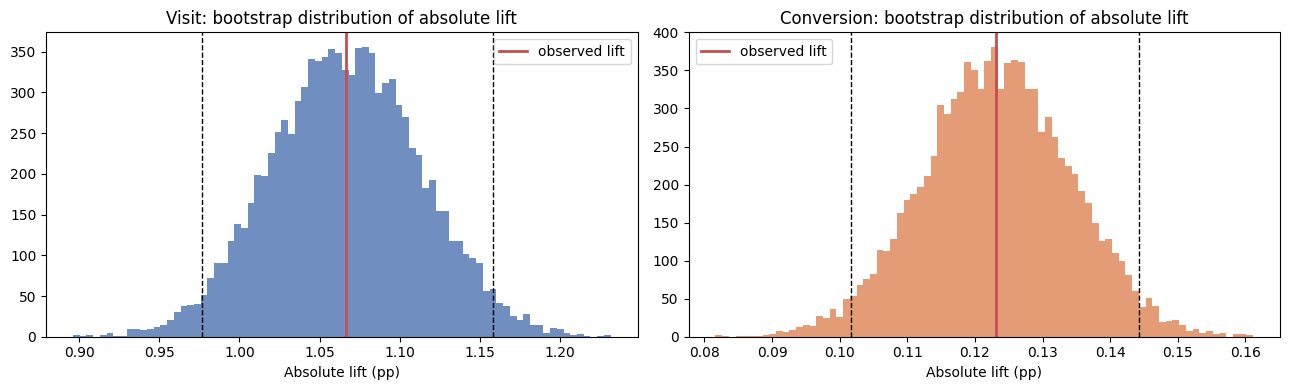

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, m, color in zip(axes, METRICS, ["#4C72B0", "#DD8452"]):
    d = boot[m]["abs_draws"] * 100
    ax.hist(d, bins=80, color=color, alpha=0.8)
    for x in boot[m]["abs_ci"] * 100:
        ax.axvline(x, color="black", ls="--", lw=1)
    ax.axvline(zt.loc[m, "abs_lift"] * 100, color="#C44E52", lw=2, label="observed lift")
    ax.set_title(f"{m.capitalize()}: bootstrap distribution of absolute lift")
    ax.set_xlabel("Absolute lift (pp)")
    ax.legend()
fig.tight_layout()
fig.savefig(FIG / "05_bootstrap.png", dpi=110)
plt.show()

## 6.3 Practical significance

A p-value only says the effect is not zero. The business needs to know **how large** it is:

In [6]:
rows = []
for m in METRICS:
    r = zt.loc[m]
    rows.append({"metric": m,
                 "extra per 1,000 assigned users": r.abs_lift * 1000,
                 "95% CI": f"[{r.abs_ci_low*1000:.2f}, {r.abs_ci_high*1000:.2f}]",
                 "extra per 1,000 exposed users (CACE)": r.abs_lift / exposure_rate * 1000})
prac = pd.DataFrame(rows).set_index("metric")
prac

,"extra per 1,000 assigned users",95% CI,"extra per 1,000 exposed users (CACE)"
metric,,,
visit,10.665398,"[9.76, 11.57]",296.202943
conversion,1.231384,"[1.02, 1.45]",34.198405


In [7]:
v = zt.loc["visit", "abs_lift"]
print(f"Every 1,000 users put into the campaign brought ~{v*1000:.1f} extra visits.")
print(f"Every 1,000 users who actually saw the ad: ~{v/exposure_rate*1000:.0f} extra visits.")
print()
print("ROI preview (assumptions: ad ₹0.50, visit ₹5):")
print(f"  Paying per assigned user: value ₹{v*VISIT_VALUE*1000:.0f} vs cost ₹{AD_COST*1000:.0f} per 1,000 users")
print(f"  Paying per impression:    value ₹{v/exposure_rate*VISIT_VALUE*1000:.0f} vs cost ₹{AD_COST*1000:.0f} per 1,000 impressions")

Every 1,000 users put into the campaign brought ~10.7 extra visits.
Every 1,000 users who actually saw the ad: ~296 extra visits.

ROI preview (assumptions: ad ₹0.50, visit ₹5):
  Paying per assigned user: value ₹53 vs cost ₹500 per 1,000 users
  Paying per impression:    value ₹1481 vs cost ₹500 per 1,000 impressions


## 6.4 Covariate-adjusted lift ⚠️ (important finding)

**Idea (CUPED / Lin regression adjustment):** the features predict visit. Adding them to a regression removes outcome noise
and tightens the CI. Under perfect randomization the adjusted and unadjusted lifts should be **almost the same**; only the CI should shrink.

Model: `visit ~ T + X_centered + T × X_centered` (Lin 2013), robust (HC2) standard errors.

In [8]:
adj = pd.DataFrame({m: regression_adjusted_effect(df, m, FEATURES) for m in METRICS + ["exposure"]}).T
unadj = pd.DataFrame({m: itt_effect(df.loc[T == 1, m].values, df.loc[T == 0, m].values) for m in METRICS + ["exposure"]}).T
comp = pd.DataFrame({"unadjusted": unadj.effect, "unadj SE": unadj.se,
                     "adjusted": adj.effect, "adj SE": adj.se, "R²": adj.r2})
comp["gap (unadj − adj)"] = comp.unadjusted - comp.adjusted
comp["gap in SEs"] = comp["gap (unadj − adj)"] / comp["unadj SE"]
comp["variance reduction"] = 1 - (comp["adj SE"] / comp["unadj SE"]) ** 2
comp

,unadjusted,unadj SE,adjusted,adj SE,R²,gap (unadj − adj),gap in SEs,variance reduction
visit,0.010665,0.000463,0.008116,0.000415,0.284471,0.002550,5.503665,0.198515
conversion,0.001231,0.000110,0.001036,0.000109,0.122354,0.000195,1.779617,0.005612
exposure,0.036007,0.000171,0.035401,0.000152,0.194771,0.000606,3.548494,0.211876


**The adjusted visit lift dropped from 1.07 pp to 0.81 pp.** That gap is ~5–6 SE. It should not happen if randomization were clean.

### Investigation: was the treatment group more active to begin with?

**Prognostic score:** train a LightGBM model **only on control** users to predict visit from the features (cross-fitted to avoid overfitting).
Then compare the average predicted visit rate of both groups. The features are measured before treatment, so under randomization
this difference should be ~0.

In [9]:
ctrl_idx, treat_idx = np.where(T == 0)[0], np.where(T == 1)[0]
y = df.visit.values
score = np.zeros(len(df))
params = dict(n_estimators=200, learning_rate=0.05, verbose=-1)
for tr, te in KFold(5, shuffle=True, random_state=0).split(ctrl_idx):
    mdl = lgb.LGBMClassifier(**params).fit(df.iloc[ctrl_idx[tr]][FEATURES], y[ctrl_idx[tr]])
    score[ctrl_idx[te]] = mdl.predict_proba(df.iloc[ctrl_idx[te]][FEATURES])[:, 1]
mdl = lgb.LGBMClassifier(**params).fit(df.iloc[ctrl_idx][FEATURES], y[ctrl_idx])
score[treat_idx] = mdl.predict_proba(df.iloc[treat_idx][FEATURES])[:, 1]

ps = itt_effect(score[T == 1], score[T == 0])
print(f"Predicted baseline visit:  T={ps['rate_t']:.4%}  C={ps['rate_c']:.4%}")
print(f"Difference = {ps['effect']*100:+.3f} pp  (SE {ps['se']*100:.3f}, z = {ps['effect']/ps['se']:.1f})")
print(f"Unadjusted lift − prognostic gap = {(unadj.loc['visit','effect'] - ps['effect'])*100:.3f} pp "
      f"vs Lin-adjusted {adj.loc['visit','effect']*100:.3f} pp")

Predicted baseline visit:  T=4.0729%  C=3.8077%
Difference = +0.265 pp  (SE 0.025, z = 10.5)
Unadjusted lift − prognostic gap = 0.801 pp vs Lin-adjusted 0.812 pp


Which features differ? The largest SMD in Step 3 was f3. Share of users at f3's default value (mode):

In [10]:
full = pd.read_parquet(Path.cwd().parent / "data" / "criteo_full.parquet", columns=["f3", "f6", "treatment"])
rows = []
for f in ["f3", "f6"]:
    mode = df[f].mode()[0]
    rows.append({"feature": f,
                 "10% T": (df.loc[T == 1, f] == mode).mean(), "10% C": (df.loc[T == 0, f] == mode).mean(),
                 "full T": (full.loc[full.treatment == 1, f] == mode).mean(),
                 "full C": (full.loc[full.treatment == 0, f] == mode).mean()})
del full
pd.DataFrame(rows).set_index("feature").style.format("{:.2%}")

,10% T,10% C,full T,full C
feature,,,,
f3,81.71%,83.05%,81.66%,83.03%
f6,26.34%,27.36%,26.37%,27.27%


### Interpretation

- The treatment group's features lean slightly toward "more active user". Expected visit is 0.27 pp higher, z ≈ 10, so this is not chance.
  The full data (14 million rows) shows the same pattern, so it is not sampling noise.
- **Most likely cause:** the Criteo dataset pools several separate incrementality tests. If those tests had different treatment ratios
  and user populations, pooling makes features and treatment correlated (a Simpson's-paradox-like effect). A supporting clue:
  the overall ratio is *exactly* 85.000% (Step 3).
- The per-feature SMDs (< 0.05) and the classifier AUC (0.511) in Step 3 both looked small. But the features predict visit strongly
  (R² 0.28), so even a small imbalance adds ~0.27 pp of bias to the lift. **Lesson: balance checks should be outcome-weighted,
  not only per feature.**

**Which number should we trust?**
- If the features are measured *before* treatment (Criteo says they are), **the adjusted lift (0.81 pp) is more accurate**.
  About 25% of the unadjusted lift was imbalance.
- If treatment affected the features (post-treatment), the adjustment would itself add bias and the unadjusted number would be right.
- So we **report a range: 0.81–1.07 pp**. The adjusted value is the primary estimate, and the ROI step (Step 9) runs sensitivity on both.
- **Uplift models (Step 8)** condition on the features, so this imbalance is handled there automatically.

### Adjusted CACE

In [11]:
adj_cace = adj.loc["visit", "effect"] / adj.loc["exposure", "effect"]
unadj_cace = unadj.loc["visit", "effect"] / unadj.loc["exposure", "effect"]
adj_cace_conv = adj.loc["conversion", "effect"] / adj.loc["exposure", "effect"]
print(f"Visit CACE:      unadjusted {unadj_cace*100:.1f} pp  ->  adjusted {adj_cace*100:.1f} pp")
print(f"Conversion CACE: unadjusted {unadj.loc['conversion','effect']/unadj.loc['exposure','effect']*100:.2f} pp  ->  adjusted {adj_cace_conv*100:.2f} pp")
print(f"Break-even (per impression) = {AD_COST/VISIT_VALUE*100:.0f} pp -> adjusted CACE is still above it")

Visit CACE:      unadjusted 29.6 pp  ->  adjusted 22.9 pp
Conversion CACE: unadjusted 3.42 pp  ->  adjusted 2.93 pp
Break-even (per impression) = 10 pp -> adjusted CACE is still above it


## 6.5 Summary chart

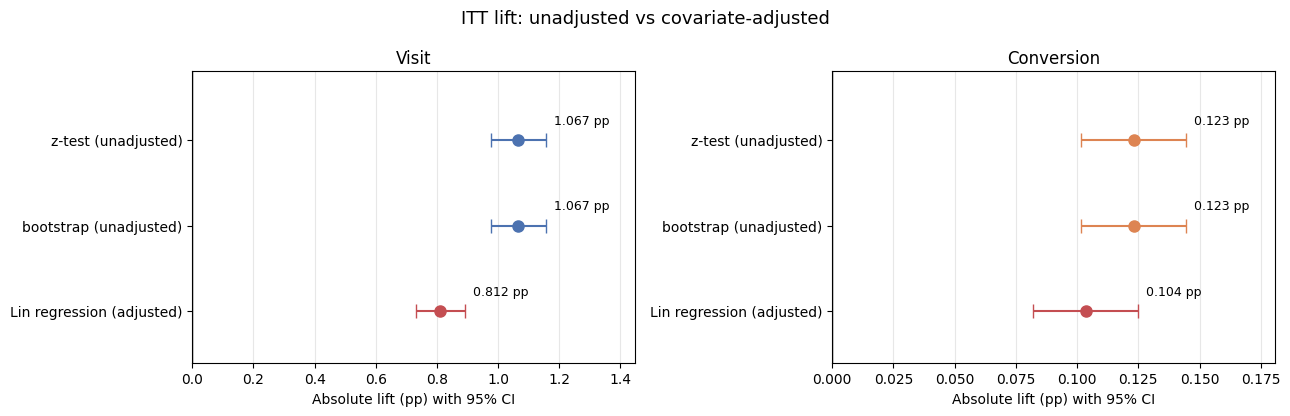

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, m, color in zip(axes, METRICS, ["#4C72B0", "#DD8452"]):
    labels = ["z-test (unadjusted)", "bootstrap (unadjusted)", "Lin regression (adjusted)"]
    pts = [zt.loc[m, "abs_lift"], zt.loc[m, "abs_lift"], adj.loc[m, "effect"]]
    lo = [zt.loc[m, "abs_ci_low"], boot[m]["abs_ci"][0], adj.loc[m, "ci_low"]]
    hi = [zt.loc[m, "abs_ci_high"], boot[m]["abs_ci"][1], adj.loc[m, "ci_high"]]
    ypos = np.arange(3)[::-1]
    for yp, p, l, h, lab in zip(ypos, pts, lo, hi, labels):
        c = "#C44E52" if "adjusted" in lab and "un" not in lab else color
        ax.errorbar(p * 100, yp, xerr=[[(p - l) * 100], [(h - p) * 100]], fmt="o", color=c, capsize=5, ms=8)
        ax.text(h * 100, yp + 0.15, f"  {p*100:.3f} pp", va="bottom", fontsize=9)
    ax.axvline(0, color="black", lw=1)
    ax.set_yticks(ypos, labels)
    ax.set_xlim(0, max(hi) * 100 * 1.25)
    ax.set_ylim(-0.6, 2.8)
    ax.set_xlabel("Absolute lift (pp) with 95% CI")
    ax.set_title(f"{m.capitalize()}")
    ax.grid(axis="x", alpha=0.3)
fig.suptitle("ITT lift: unadjusted vs covariate-adjusted", fontsize=13)
fig.tight_layout()
fig.savefig(FIG / "05_lift_ci.png", dpi=110)
plt.show()

## Summary

In [13]:
for m in METRICS:
    r = zt.loc[m]
    print(f"{m.upper()}")
    print(f"  Unadjusted: {r.abs_lift*100:+.3f} pp [{r.abs_ci_low*100:.3f}, {r.abs_ci_high*100:.3f}], rel {r.rel_lift:+.1%} [{r.rel_ci_low:+.1%}, {r.rel_ci_high:+.1%}], p={r.p_value:.1e}")
    print(f"  Bootstrap:  [{boot[m]['abs_ci'][0]*100:.3f}, {boot[m]['abs_ci'][1]*100:.3f}]")
    print(f"  Adjusted:   {adj.loc[m,'effect']*100:+.3f} pp [{adj.loc[m,'ci_low']*100:.3f}, {adj.loc[m,'ci_high']*100:.3f}], "
          f"rel {adj.loc[m,'effect']/zt.loc[m,'rate_c']:+.1%}")
print(f"\nPrognostic imbalance: {ps['effect']*100:+.3f} pp (z={ps['effect']/ps['se']:.1f})")
print(f"CACE visit: unadjusted {unadj_cace*100:.1f} pp, adjusted {adj_cace*100:.1f} pp")

VISIT
  Unadjusted: +1.067 pp [0.976, 1.157], rel +27.9% [+25.0%, +30.9%], p=9.2e-100
  Bootstrap:  [0.977, 1.158]
  Adjusted:   +0.812 pp [0.730, 0.893], rel +21.3%
CONVERSION
  Unadjusted: +0.123 pp [0.102, 0.145], rel +62.7% [+47.0%, +80.1%], p=2.6e-21
  Bootstrap:  [0.102, 0.144]
  Adjusted:   +0.104 pp [0.082, 0.125], rel +52.7%

Prognostic imbalance: +0.265 pp (z=10.5)
CACE visit: unadjusted 29.6 pp, adjusted 22.9 pp


## Key takeaways (Step 6)

1. **Visit (primary):** +1.07 pp [0.98, 1.16], relative **+27.9%** [+25.0%, +30.9%], z = 21, p ≈ 1e-100.
2. **Conversion (secondary):** +0.12 pp [0.10, 0.14], relative **+62.7%** [+47.0%, +80.1%], z = 9.5, p ≈ 3e-21.
   The relative CI is wide because conversion is rare (consistent with Step 5).
3. **Bootstrap (10k) CIs match the z-test almost exactly.** At this sample size the normal approximation is fine.
4. **Practical significance:** **~10.7 extra visits** and ~1.2 extra conversions per 1,000 assigned users.
   ~296 extra visits per 1,000 *exposed* users.
5. **⚠️ Covariate adjustment exposed an imbalance:** Lin regression gives a visit lift of **0.81 pp** [0.73, 0.89], ~25% lower than unadjusted (gap ≈ 5.5 SE).
   By the prognostic score, the treatment group's *expected* visit rate was 0.27 pp higher (z = 10.5), and the full data shows the same.
   Two independent methods (Lin regression 0.81, prognostic score 0.80) agree.
   Likely cause: the dataset pools several tests.
6. **Final estimate:** a visit-lift **range of 0.81–1.07 pp**. Primary = adjusted 0.81 pp (+21%), assuming the features are pre-treatment.
   Adjusted CACE ≈ **22.9 pp** (unadjusted 29.6 pp). Both are above the 10 pp break-even.
7. **ROI preview:** if the cost is paid per assigned user, value is ₹53 vs ₹500 cost per 1,000 users, i.e. a loss.
   If the cost is paid per impression, value is ~₹1,100–1,480 vs ₹500 cost per 1,000 impressions, i.e. a profit. Step 9 does the full analysis.

**Lesson (interview point):** |SMD| < 0.1 on every feature does not guarantee balance. When features strongly predict the outcome,
many small imbalances can add up to a large bias. A **prognostic score balance** check is essential.